# Travail Pratique 2 : Introductionau Traitement et Analyse d'Image

#### 1. Filtre moyenneur (Averaging filter)

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
img = cv2.imread('gray_disc.png', cv2.IMREAD_GRAYSCALE)

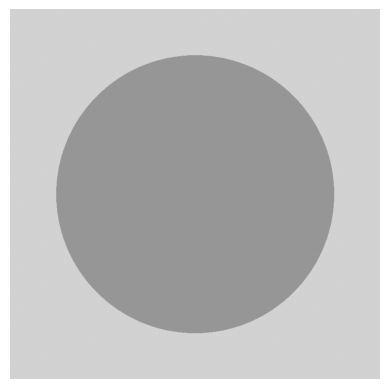

In [8]:
plt.imshow(img, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [10]:
h1 = np.ones((5, 5), np.float32) / 25   
h2 = np.ones((11, 11), np.float32) / 121 

filtered_h1 = cv2.filter2D(img, -1, h1)
filtered_h2 = cv2.filter2D(img, -1, h2)

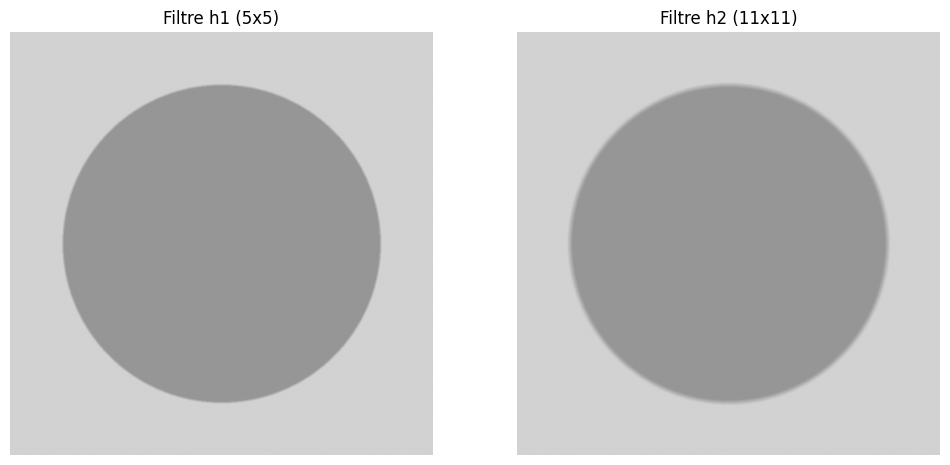

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(filtered_h1, cmap='gray', vmin=0, vmax=255) 
plt.title('Filtre h1 (5x5)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_h2, cmap='gray', vmin=0, vmax=255)
plt.title('Filtre h2 (11x11)')
plt.axis('off')

plt.show()

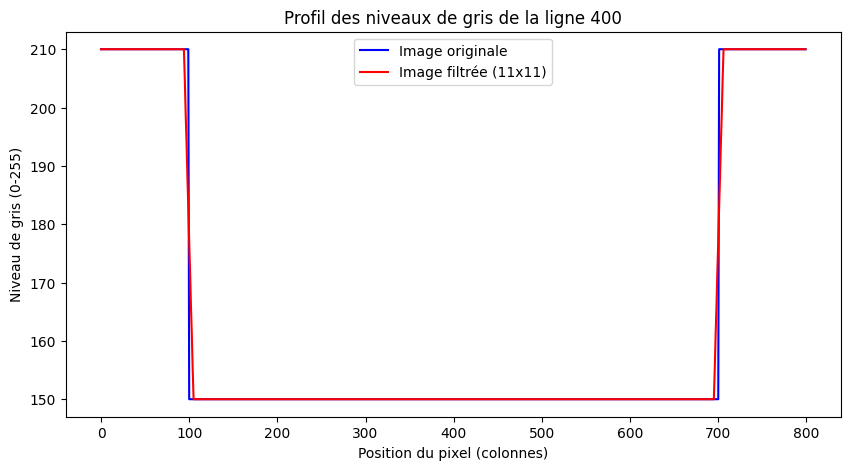

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(img[400, :], label='Image originale', color='blue')
plt.plot(filtered_h2[400, :], label='Image filtrée (11x11)', color='red')
plt.title("Profil des niveaux de gris de la ligne 400")
plt.xlabel("Position du pixel (colonnes)")
plt.ylabel("Niveau de gris (0-255)")
plt.legend()
plt.show()

In [15]:
noised_img = cv2.imread('gray_disc_noised_gaussian.png', cv2.IMREAD_GRAYSCALE)

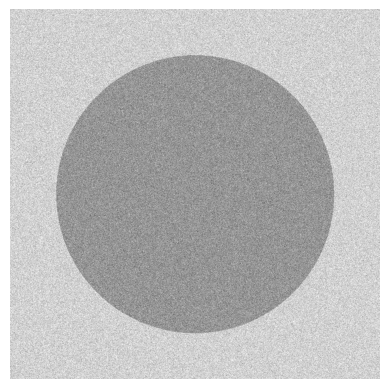

In [18]:
plt.imshow(noised_img, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [20]:
noised_filtered_h1 = cv2.filter2D(noised_img, -1, h1)
noised_filtered_h2 = cv2.filter2D(noised_img, -1, h2)

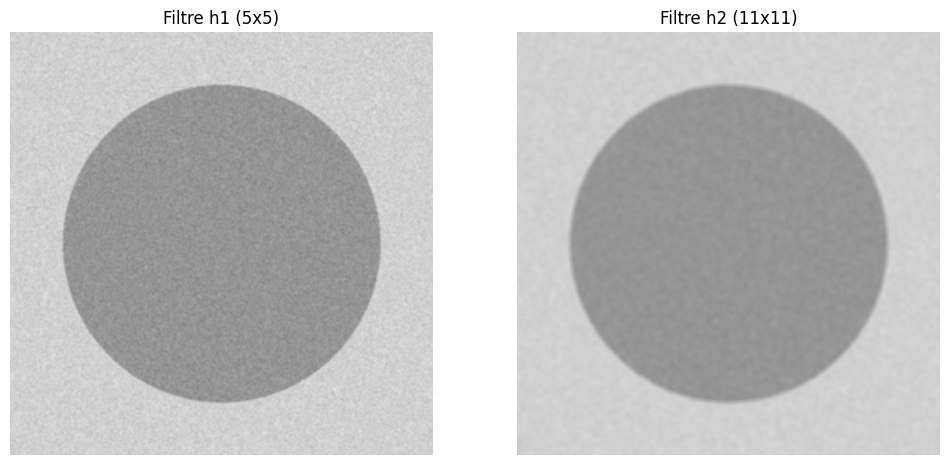

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Ajout de vmin=0, vmax=255 pour empêcher le contraste automatique
plt.subplot(1, 2, 1)
plt.imshow(noised_filtered_h1, cmap='gray', vmin=0, vmax=255) 
plt.title('Filtre h1 (5x5)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(noised_filtered_h2, cmap='gray', vmin=0, vmax=255)
plt.title('Filtre h2 (11x11)')
plt.axis('off')

plt.show()

#### 2. Filtre médian (Median filter)

In [26]:
noised_sp = cv2.imread('gray_disc_noised_s&p.png', cv2.IMREAD_GRAYSCALE)

In [28]:
if noised_sp is None:
    print("Erreur : l'image 'gray2_disc_noised_s&p.png' n'a pas été trouvée.")

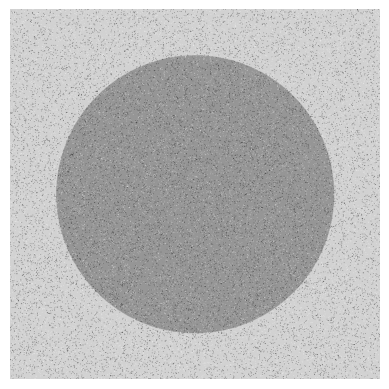

In [30]:
plt.imshow(noised_sp, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [32]:
denoised_median = cv2.medianBlur(noised_sp, 9)

In [34]:
h2 = np.ones((11, 11), np.float32) / 121

denoised_mean = cv2.filter2D(noised_sp, -1, h2)

In [36]:
noised_img_gaussian = cv2.imread('gray_disc_noised_gaussian.png', cv2.IMREAD_GRAYSCALE)

if noised_img_gaussian is not None:
    # 2.5) Application du filtre médian (taille 9) sur le bruit gaussien
    denoised_gaussian_median = cv2.medianBlur(noised_img_gaussian, 9)

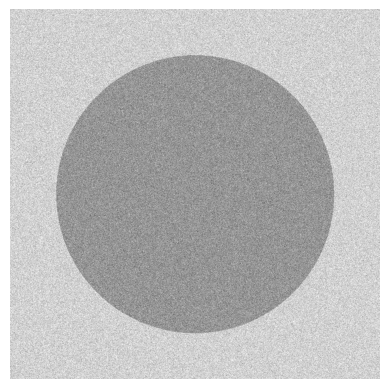

In [38]:
plt.imshow(noised_img_gaussian, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

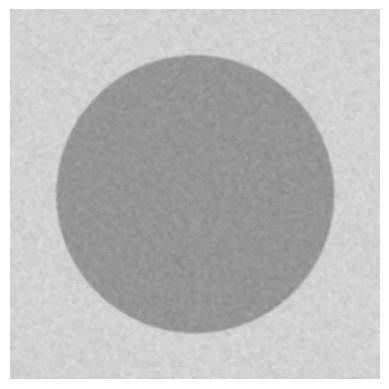

In [40]:
plt.imshow(denoised_gaussian_median, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

#### 3. En coulisses (Behind the scene)

In [116]:
!pip install scikit-image

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.8 MB 144.6 kB/s eta 0:01:25
   - -------------------------------------- 0.5/12.8 MB 144.6 kB/s eta 0:01:25
  

In [43]:
from skimage.util import random_noise

In [45]:
image_path = 'gray_disc.png' 
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is not None:
    generated_gaussian = random_noise(img, mode='gaussian')
    generated_gaussian = (generated_gaussian * 255).astype(np.uint8)

    generated_sp = random_noise(img, mode='s&p')

    generated_sp = (generated_sp * 255).astype(np.uint8)

    print("Succès : Les images bruitées ont été générées artificiellement !")

Succès : Les images bruitées ont été générées artificiellement !


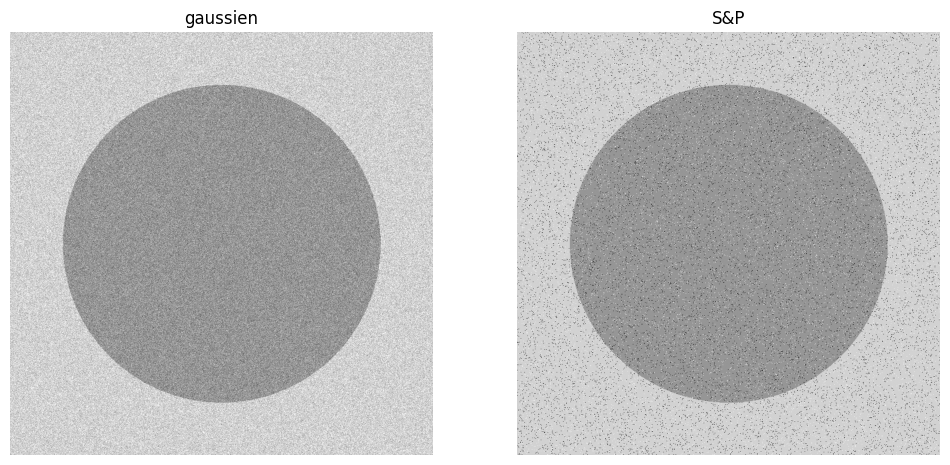

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(generated_gaussian, cmap='gray', vmin=0, vmax=255) 
plt.title('gaussien')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(generated_sp, cmap='gray', vmin=0, vmax=255)
plt.title('S&P')
plt.axis('off')

plt.show()

In [49]:
def myConvolution(image, kernel):
    h_img, w_img = image.shape
    h_k, w_k = kernel.shape
    
    pad_h = h_k // 2
    pad_w = w_k // 2
    
    padded_img = cv2.copyMakeBorder(image, pad_h, pad_h, pad_w, pad_w, cv2.BORDER_REPLICATE)
    
    output = np.zeros((h_img, w_img), dtype=np.float32)
    
    for i in range(h_img):
        for j in range(w_img):
            roi = padded_img[i:i+h_k, j:j+w_k]
            
            output[i, j] = np.sum(roi * kernel)
            
    output = np.clip(output, 0, 255).astype(np.uint8)
    
    return output

h2 = np.ones((11, 11), np.float32) / 121

my_result = myConvolution(img, h2)

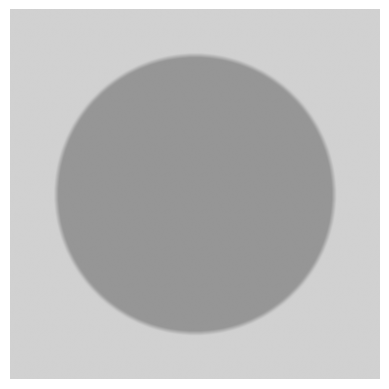

In [51]:
plt.imshow(my_result, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()

In [53]:
def myMedianFilter(image, kernel_size):
    h_img, w_img = image.shape
    pad = kernel_size // 2
    
    padded_img = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    
    output = np.zeros((h_img, w_img), dtype=np.uint8)
    
    for i in range(h_img):
        for j in range(w_img):
            roi = padded_img[i:i+kernel_size, j:j+kernel_size]
            
            output[i, j] = np.median(roi)
            
    return output

if 'generated_sp' in locals():
    my_median_result = myMedianFilter(generated_sp, 9)
    print("Succès : Le filtrage médian personnalisé a été appliqué !")

Succès : Le filtrage médian personnalisé a été appliqué !


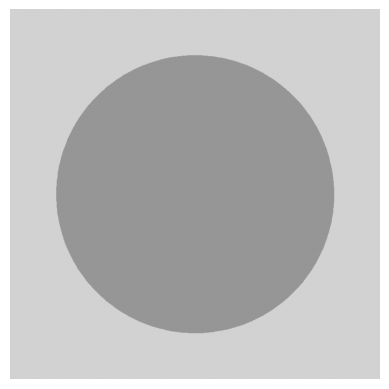

In [55]:
plt.imshow(my_median_result, cmap='gray', vmin=0, vmax=255) 
plt.axis('off')
plt.show()